In [2]:
import pandas as pd

# 1. Load your processed price data (to know which 459 tickers are valid)
in_sample = pd.read_csv("data/processed/sp500_in_sample.csv", index_col=0, parse_dates=True)
full_list = pd.read_csv("data/raw/sp500list.csv")

subsector_dict = {}

for ticker in in_sample.columns:
    subsector_for_ticker = full_list.loc[full_list['symbol'] == ticker, 'sub_industry'].values[0]
    subsector_dict.setdefault(subsector_for_ticker, []).append(ticker)

for sector, tickers in sorted(subsector_dict.items()):
    print(f"{sector:<28}: {len(tickers)} tickers (e.g., {tickers[:3]})")

Advertising                 : 1 tickers (e.g., ['OMC'])
Aerospace & Defense         : 10 tickers (e.g., ['BA', 'GD', 'HII'])
Agricultural & Farm Machinery: 1 tickers (e.g., ['DE'])
Agricultural Products       : 1 tickers (e.g., ['ADM'])
Air Freight & Logistics     : 4 tickers (e.g., ['CHRW', 'EXPD', 'FDX'])
Airlines                    : 5 tickers (e.g., ['AAL', 'ALK', 'DAL'])
Alternative Carriers        : 1 tickers (e.g., ['LUMN'])
Apparel Retail              : 2 tickers (e.g., ['ROST', 'TJX'])
Apparel, Accessories & Luxury Goods: 4 tickers (e.g., ['NKE', 'RL', 'TPR'])
Application Software        : 10 tickers (e.g., ['ADBE', 'ADSK', 'CDNS'])
Asset Management & Custody Banks: 7 tickers (e.g., ['AMP', 'BEN', 'BLK'])
Auto Parts & Equipment      : 2 tickers (e.g., ['APTV', 'BWA'])
Automobile Manufacturers    : 3 tickers (e.g., ['F', 'GM', 'TSLA'])
Automotive Retail           : 2 tickers (e.g., ['AAP', 'KMX'])
Biotechnology               : 7 tickers (e.g., ['AMGN', 'BIIB', 'GILD'])
Brewers 

In [3]:
from itertools import combinations
from statsmodels.tsa.stattools import coint
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Compute in-sample daily log returns (to compare return correlation vs. cointegration)
in_sample_returns = in_sample.diff().dropna()

results = []

for sector, tickers in sorted(subsector_dict.items()):    
    for stock_a, stock_b in combinations(tickers, 2):
        # Engle-Granger cointegration test on in-sample log prices
        t_stat, p_value, _ = coint(in_sample[stock_a], in_sample[stock_b])
        
        # In-sample return correlation
        corr = in_sample_returns[stock_a].corr(in_sample_returns[stock_b])
        
        results.append({
            "Sector": sector,
            "Stock_A": stock_a,
            "Stock_B": stock_b,
            "t_stat": t_stat,
            "p_value": p_value,
            "Return_Corr": corr
        })

# 2. Deliverable: Cointegration p-value table sorted by significance
coint_table = pd.DataFrame(results).sort_values("p_value").reset_index(drop=True)
coint_table.to_csv("data/processed/coint_results.csv", index=False)

print(f"\nScan complete! Total pairs tested: {len(coint_table)}")
print(f"Pairs with p < 0.01: {(coint_table['p_value'] < 0.01).sum()}")
print(f"Pairs with p < 0.05: {(coint_table['p_value'] < 0.05).sum()}")
print(f"Pairs with p < 0.10: {(coint_table['p_value'] < 0.10).sum()}")
print("\nTop 15 Candidate Cointegrated Pairs:")
print(coint_table.head(15))


Scan complete! Total pairs tested: 1244
Pairs with p < 0.01: 37
Pairs with p < 0.05: 113
Pairs with p < 0.10: 206

Top 15 Candidate Cointegrated Pairs:
                                Sector Stock_A Stock_B    t_stat   p_value  \
0   Oil & Gas Exploration & Production     APA     EOG -5.642289  0.000009   
1   Oil & Gas Exploration & Production     APA     EQT -5.392926  0.000029   
2   Oil & Gas Exploration & Production     APA     DVN -5.250540  0.000056   
3   Oil & Gas Storage & Transportation    TRGP     WMB -4.900314  0.000250   
4        Property & Casualty Insurance     AIG     HIG -4.865240  0.000289   
5     Asset Management & Custody Banks     BEN     STT -4.793827  0.000387   
6                 Industrial Machinery      IR      PH -4.790073  0.000393   
7        Property & Casualty Insurance     AIG      CB -4.687125  0.000593   
8                         Homebuilding     LEN     NVR -4.580779  0.000899   
9                         Homebuilding     DHI     LEN -4.540514  0

In [ ]:
#Testing different p_values
stand_results = pd.read_csv("data/processed/coint_results.csv", index_col=0, parse_dates=True)
p_vals = [0.01, 0.05, 0.1]

for p_val in p_vals:
    subset = stand_results[stand_results['p_value'] < p_val]
    subset.to_csv(f'standard_coint_pairs_p{p_val}.csv', index=False)

/var/folders/vp/sf1yj1mj1s587f2m70xcdgzw0000gn/T/ipykernel_33214/3077832256.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  stand_results = pd.read_csv("data/processed/coint_results.csv", index_col=0, parse_dates=True)


In [4]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from itertools import combinations
from statsmodels.tsa.stattools import coint

# --- Helper: Ornstein-Uhlenbeck Half-Life of Mean Reversion ---
def calculate_half_life(spread: pd.Series) -> float:
    spread_lag = spread.shift(1).dropna()
    spread_ret = spread.diff().dropna()
    model = sm.OLS(spread_ret, sm.add_constant(spread_lag)).fit()
    lam = model.params.iloc[1]
    if lam >= 0:
        return np.inf
    return -np.log(2) / np.log(1 + lam)

# --- 1. Build Sub-Industry Groups (Multi-stock sub-industries only) ---
# (Change 'gics_sub_industry' to match your exact column name in full_list)
sub_col = [c for c in full_list.columns if "sub" in c.lower()][0]

sub_dict = {}
for ticker in in_sample.columns:
    matches = full_list.loc[full_list["symbol"] == ticker, sub_col]
    if not matches.empty:
        sub_dict.setdefault(matches.iloc[-1], []).append(ticker)

# Keep sub-industries with >= 2 tickers (Option 1)
active_groups = {k: v for k, v in sub_dict.items() if len(v) >= 2}

# --- 2. Precompute Returns & Split In-Sample into Two Halves (Filter 5) ---
in_sample_returns = in_sample.diff().dropna()
mid_idx = len(in_sample) // 2
in_sample_h1 = in_sample.iloc[:mid_idx]
in_sample_h2 = in_sample.iloc[mid_idx:]

strong_pairs = []

for group, tickers in sorted(active_groups.items()):
    for a, b in combinations(tickers, 2):
        # Filter 4a: Minimum daily return correlation (fast check first)
        corr = in_sample_returns[a].corr(in_sample_returns[b])
        if corr < 0.50:
            continue

        # Filter 2: Bidirectional Engle-Granger cointegration on full in-sample
        _, p_ab, _ = coint(in_sample[a], in_sample[b])
        _, p_ba, _ = coint(in_sample[b], in_sample[a])
        max_p = max(p_ab, p_ba)
        if max_p >= 0.1:
            continue

        # Filter 5: Sub-period stability check (must hold p < 0.10 in BOTH halves)
        _, p_h1, _ = coint(in_sample_h1[a], in_sample_h1[b])
        _, p_h2, _ = coint(in_sample_h2[a], in_sample_h2[b])
        if p_h2 >= 0.10 or p_h1 >= 0.40:
            continue

        # Filter 4b: Reasonable OLS hedge ratio (0.3 <= beta <= 3.0)
        ols = sm.OLS(in_sample[a], sm.add_constant(in_sample[b])).fit()
        beta = ols.params[b]
        alpha = ols.params["const"]
        if not (0.3 <= beta <= 3.0):
            continue

        # Filter 3: Half-life of mean reversion (5 to 45 trading days)
        spread = in_sample[a] - beta * in_sample[b] - alpha
        half_life = calculate_half_life(spread)
        if not (5 <= half_life <= 65):
            continue

        strong_pairs.append({
            "Sub_Industry": group,
            "Stock_A": a,
            "Stock_B": b,
            "p_value_max": max_p,
            "p_H1": p_h1,
            "p_H2": p_h2,
            "Return_Corr": corr,
            "Hedge_Ratio": beta,
            "Half_Life_Days": half_life
        })

strong_df = pd.DataFrame(strong_pairs).sort_values("p_value_max").reset_index(drop=True)

print(f"High-conviction pairs passing all 5 filters: {len(strong_df)}")
print(strong_df)

#testing different p_values
p_vals = [0.01, 0.05, 0.1]
for p_val in p_vals:
    p_subset = strong_df[strong_df['p_value_max'] < p_val]
    p_subset.to_csv(f"data/processed/filtered_coint_pairs_p{p_val}.csv", index=False)

High-conviction pairs passing all 5 filters: 21
                             Sub_Industry Stock_A Stock_B  p_value_max  \
0                    Industrial Machinery      IR      PH     0.000393   
1                            Homebuilding     DHI     LEN     0.001050   
2                            Homebuilding     LEN     NVR     0.001312   
3                            Homebuilding     DHI     NVR     0.002272   
4           Property & Casualty Insurance     AIG      CB     0.003421   
5                    Application Software    CDNS    SNPS     0.006062   
6                             Restaurants     DRI     YUM     0.006906   
7                      Electric Utilities     AEP     ETR     0.009766   
8   Data Processing & Outsourced Services      MA       V     0.014830   
9   Construction Machinery & Heavy Trucks     CAT     WAB     0.015142   
10     Oil & Gas Storage & Transportation     OKE    TRGP     0.029725   
11                    Managed Health Care     ELV     MOH     0.

In [6]:
classic_pairs = [("KO", "PEP"), ("HD", "LOW"), ("XOM", "CVX"), ("JPM", "BAC"), ("GOOGL", "META")]
in_sample_returns = in_sample.diff().dropna()

print(f"{'Pair':<12} | {'Return Corr':<12} | {'In-Sample p-val':<15} | {'Why It Passed/Failed'}")
print("-" * 70)
for a, b in classic_pairs:
    if a in in_sample.columns and b in in_sample.columns:
        corr = in_sample_returns[a].corr(in_sample_returns[b])
        _, p_val, _ = coint(in_sample[a], in_sample[b])
        status = "Cointegrated" if p_val < 0.05 else "High Corr, Non-Stationary Drift"
        print(f"{a+'/'+b:<12} | {corr:<12.3f} | {p_val:<15.4f} | {status}")

Pair         | Return Corr  | In-Sample p-val | Why It Passed/Failed
----------------------------------------------------------------------
KO/PEP       | 0.777        | 0.0470          | Cointegrated
HD/LOW       | 0.878        | 0.2754          | High Corr, Non-Stationary Drift
XOM/CVX      | 0.860        | 0.1044          | High Corr, Non-Stationary Drift
JPM/BAC      | 0.907        | 0.9925          | High Corr, Non-Stationary Drift
GOOGL/META   | 0.654        | 0.6207          | High Corr, Non-Stationary Drift


In [7]:
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Map all 6 uploaded candidate pair CSV files
pair_universes = {
    "Filtered (p < 0.01)": pd.read_csv("data/processed/filtered_coint_pairs_p0.01.csv"),
    "Filtered (p < 0.05)": pd.read_csv("data/processed/filtered_coint_pairs_p0.05.csv"),
    "Filtered (p < 0.10)": pd.read_csv("data/processed/filtered_coint_pairs_p0.1.csv"),
    "Standard EG (p < 0.01)": pd.read_csv("data/processed/standard_coint_pairs_p0.01.csv"),
    "Standard EG (p < 0.05)": pd.read_csv("data/processed/standard_coint_pairs_p0.05.csv"),
    "Standard EG (p < 0.10)": pd.read_csv("data/processed/standard_coint_pairs_p0.1.csv"),
}

for label, df in pair_universes.items():
    print(f"{label:<24}: {len(df):>3} candidate pairs")

# 2. Load chronological log-price splits (70% In-Sample / 30% Out-of-Sample)
is_path = "data/processed/sp500_in_sample.csv"
oos_path = "data/processed/sp500_out_of_sample.csv"

if os.path.exists(is_path) and os.path.exists(oos_path):
    in_sample = pd.read_csv(is_path, index_col=0, parse_dates=True)
    out_of_sample = pd.read_csv(oos_path, index_col=0, parse_dates=True)
else:
    # Standalone fallback: downloads tickers via yfinance if local splits are in another folder
    import yfinance as yf
    all_tickers = sorted({
        t for df in pair_universes.values()
        for t in pd.concat([df["Stock_A"], df["Stock_B"]]).unique()
    })
    raw = yf.download(all_tickers, start="2020-01-01", end="2025-12-31", auto_adjust=True)["Close"]
    log_prices = np.log(raw.dropna(axis=1, how="any"))
    split_idx = int(len(log_prices) * 0.70)
    in_sample = log_prices.iloc[:split_idx]
    out_of_sample = log_prices.iloc[split_idx:]

full_prices = pd.concat([in_sample, out_of_sample])
split_date = in_sample.index[-1]

print(f"\nIn-Sample Period    : {in_sample.index.min().date()} to {split_date.date()} ({len(in_sample)} trading days)")
print(f"Out-of-Sample Period: {out_of_sample.index.min().date()} to {out_of_sample.index.max().date()} ({len(out_of_sample)} trading days)")

def run_pair_backtest(
    prices_df: pd.DataFrame,
    stock_a: str,
    stock_b: str,
    split_dt: pd.Timestamp,
    lookback: int = 60,
    hedge_lookback: int = 120,
    hedge_mode: str = "static",   # "static" (In-Sample OLS) or "rolling" (causal rolling OLS with intercept)
    entry_z: float = 2.0,
    exit_z: float = 0.0,
    stop_z: float = 4.0,
    max_hold: int = 45,
    cost_bps: float = 5.0
):
    """
    Estimates hedge ratio (alpha, beta), constructs spread & causal rolling Z-score,
    and simulates daily net returns and round-trip trade logs for a single pair.
    """
    df = prices_df[[stock_a, stock_b]].copy()

    # Step 5a: Estimate Hedge Ratio without look-ahead bias
    if hedge_mode == "static":
        is_slice = df.loc[:split_dt]
        ols = sm.OLS(is_slice[stock_a], sm.add_constant(is_slice[stock_b])).fit()
        df["alpha"] = ols.params["const"]
        df["beta"] = ols.params[stock_b]
    elif hedge_mode == "rolling":
        cov = df[stock_a].rolling(hedge_lookback).cov(df[stock_b])
        var = df[stock_b].rolling(hedge_lookback).var()
        beta_unshifted = cov / var
        alpha_unshifted = (
            df[stock_a].rolling(hedge_lookback).mean()
            - beta_unshifted * df[stock_b].rolling(hedge_lookback).mean()
        )
        df["beta"] = beta_unshifted.shift(1)
        df["alpha"] = alpha_unshifted.shift(1)
    else:
        raise ValueError("hedge_mode must be 'static' or 'rolling'")

    # Step 5b: Compute Cointegrated Spread & Causal Rolling Z-Score
    df["spread"] = df[stock_a] - (df["alpha"] + df["beta"] * df[stock_b])
    df["roll_mean"] = df["spread"].rolling(lookback).mean().shift(1)
    df["roll_std"] = df["spread"].rolling(lookback).std().shift(1)
    df["z_score"] = (df["spread"] - df["roll_mean"]) / df["roll_std"]

    # Step 6a: Execution State Machine (+1 = Long Spread, -1 = Short Spread)
    n = len(df)
    pos = np.zeros(n)
    z_vals = df["z_score"].values
    dates = df.index

    days_held = 0
    entry_idx = None
    entry_z_val = None
    wait_for_reset = False
    trades = []

    for t in range(1, n):
        z = z_vals[t]
        prev_pos = pos[t - 1]
        if np.isnan(z):
            continue

        # Reset cool-down once Z-score returns inside [-entry_z, +entry_z]
        if wait_for_reset and abs(z) < entry_z:
            wait_for_reset = False

        if prev_pos == 0:
            if not wait_for_reset:
                if -stop_z < z < -entry_z:
                    pos[t] = 1
                    days_held = 1
                    entry_idx = t
                    entry_z_val = z
                elif entry_z < z < stop_z:
                    pos[t] = -1
                    days_held = 1
                    entry_idx = t
                    entry_z_val = z

        elif prev_pos == 1:
            days_held += 1
            if z >= -exit_z or z <= -stop_z or days_held >= max_hold:
                pos[t] = 0
                reason = "Mean Revert" if z >= -exit_z else ("Stop Loss" if z <= -stop_z else "Max Hold")
                if reason != "Mean Revert":
                    wait_for_reset = True
                trades.append({
                    "Pair": f"{stock_a}/{stock_b}",
                    "Direction": "Long Spread",
                    "Entry_Date": dates[entry_idx],
                    "Exit_Date": dates[t],
                    "Period": "In-Sample" if dates[entry_idx] <= split_dt else "Out-of-Sample",
                    "Hold_Days": days_held,
                    "Entry_Z": round(entry_z_val, 2),
                    "Exit_Z": round(z, 2),
                    "Exit_Reason": reason
                })
                days_held = 0
            else:
                pos[t] = 1

        elif prev_pos == -1:
            days_held += 1
            if z <= exit_z or z >= stop_z or days_held >= max_hold:
                pos[t] = 0
                reason = "Mean Revert" if z <= exit_z else ("Stop Loss" if z >= stop_z else "Max Hold")
                if reason != "Mean Revert":
                    wait_for_reset = True
                trades.append({
                    "Pair": f"{stock_a}/{stock_b}",
                    "Direction": "Short Spread",
                    "Entry_Date": dates[entry_idx],
                    "Exit_Date": dates[t],
                    "Period": "In-Sample" if dates[entry_idx] <= split_dt else "Out-of-Sample",
                    "Hold_Days": days_held,
                    "Entry_Z": round(entry_z_val, 2),
                    "Exit_Z": round(z, 2),
                    "Exit_Reason": reason
                })
                days_held = 0
            else:
                pos[t] = -1

    df["position"] = pos

    # Step 6b: Capital-Normalized Daily Returns & Transaction Costs
    ret_a = df[stock_a].diff()
    ret_b = df[stock_b].diff()
    gross_exposure = 1.0 + df["beta"].abs()

    df["gross_ret"] = (df["position"].shift(1) * (ret_a - df["beta"] * ret_b) / gross_exposure).fillna(0)
    df["turnover"] = df["position"].diff().abs().fillna(0)
    df["cost"] = df["turnover"] * (cost_bps / 10000.0)
    df["net_ret"] = df["gross_ret"] - df["cost"]

    # Calculate compounded gross and net return per round-trip trade
    for tr in trades:
        tr_slice = df.loc[tr["Entry_Date"]:tr["Exit_Date"]].iloc[1:]
        tr["Gross_Return"] = (1 + tr_slice["gross_ret"]).prod() - 1
        tr["Net_Return"] = tr["Gross_Return"] - (2.0 * cost_bps / 10000.0)

    return df, pd.DataFrame(trades)

def compute_period_metrics(daily_ret: pd.Series, turnover_series: pd.Series, trades_sub: pd.DataFrame):
    ann_ret = daily_ret.mean() * 252
    ann_vol = daily_ret.std() * np.sqrt(252)
    sharpe = ann_ret / ann_vol if ann_vol > 0 else 0.0
    cum = (1 + daily_ret).cumprod()
    max_dd = (cum / cum.cummax() - 1).min()
    ann_turnover = turnover_series.mean() * 252

    if len(trades_sub) > 0:
        win_rate = (trades_sub["Net_Return"] > 0).mean()
        avg_trade = trades_sub["Net_Return"].mean()
    else:
        win_rate, avg_trade = 0.0, 0.0

    return {
        "Sharpe": round(sharpe, 2),
        "Ann_Ret": f"{ann_ret:.2%}",
        "Ann_Vol": f"{ann_vol:.2%}",
        "Max_DD": f"{max_dd:.2%}",
        "Win_Rate": f"{win_rate:.1%}",
        "Avg_Trade": f"{avg_trade:.2%}",
        "Turnover": f"{ann_turnover:.2f}x",
        "_raw_sharpe": sharpe
    }

def evaluate_universe(pairs_df: pd.DataFrame, split_dt: pd.Timestamp, deduplicate_hubs: bool = False, **kwargs):
    """
    Runs run_pair_backtest across all pairs in pairs_df and aggregates into an
    equal-weighted portfolio. Optionally deduplicates overlapping tickers.
    """
    working_df = pairs_df.copy()
    if deduplicate_hubs:
        used_tickers = set()
        keep_rows = []
        for idx, row in working_df.iterrows():
            a, b = row["Stock_A"], row["Stock_B"]
            if a not in used_tickers and b not in used_tickers:
                keep_rows.append(idx)
                used_tickers.update([a, b])
        working_df = working_df.loc[keep_rows]

    pair_rets = {}
    pair_turns = {}
    all_trades = []
    pair_dfs = {}

    for _, row in working_df.iterrows():
        a, b = row["Stock_A"], row["Stock_B"]
        if a not in full_prices.columns or b not in full_prices.columns:
            continue
        df_res, tr_df = run_pair_backtest(full_prices, a, b, split_dt, **kwargs)
        pair_rets[f"{a}/{b}"] = df_res["net_ret"]
        pair_turns[f"{a}/{b}"] = df_res["turnover"]
        pair_dfs[f"{a}/{b}"] = df_res
        if not tr_df.empty:
            all_trades.append(tr_df)

    port_ret = pd.DataFrame(pair_rets).mean(axis=1)
    port_turn = pd.DataFrame(pair_turns).mean(axis=1)
    trades_master = pd.concat(all_trades, ignore_index=True) if all_trades else pd.DataFrame()

    is_ret = port_ret.loc[:split_dt]
    oos_ret = port_ret.loc[split_dt:].iloc[1:]
    is_turn = port_turn.loc[:split_dt]
    oos_turn = port_turn.loc[split_dt:].iloc[1:]

    is_trades = trades_master[trades_master["Period"] == "In-Sample"] if not trades_master.empty else pd.DataFrame()
    oos_trades = trades_master[trades_master["Period"] == "Out-of-Sample"] if not trades_master.empty else pd.DataFrame()

    is_metrics = compute_period_metrics(is_ret, is_turn, is_trades)
    oos_metrics = compute_period_metrics(oos_ret, oos_turn, oos_trades)

    return is_metrics, oos_metrics, port_ret, trades_master, pair_dfs

# Evaluate all 6 candidate CSV files
summary_rows = []
equity_curves = {}
universe_trade_logs = {}
universe_pair_dfs = {}

for name, df_pairs in pair_universes.items():
    is_m, oos_m, port_ret, t_log, p_dfs = evaluate_universe(
        df_pairs, split_date, lookback=60, hedge_mode="static",
        entry_z=2.0, exit_z=0.0, stop_z=4.0, max_hold=45, cost_bps=5.0
    )
    equity_curves[name] = (1 + port_ret).cumprod()
    universe_trade_logs[name] = t_log
    universe_pair_dfs[name] = p_dfs

    summary_rows.append({
        "Universe": name,
        "Pairs": len(df_pairs),
        "IS_Sharpe": is_m["Sharpe"],
        "IS_Ret": is_m["Ann_Ret"],
        "IS_Vol": is_m["Ann_Vol"],
        "IS_MaxDD": is_m["Max_DD"],
        "IS_WinRate": is_m["Win_Rate"],
        "OOS_Sharpe": oos_m["Sharpe"],
        "OOS_Ret": oos_m["Ann_Ret"],
        "OOS_Vol": oos_m["Ann_Vol"],
        "OOS_MaxDD": oos_m["Max_DD"],
        "OOS_WinRate": oos_m["Win_Rate"],
        "OOS_AvgTrade": oos_m["Avg_Trade"],
        "OOS_Turnover": oos_m["Turnover"],
    })

performance_table = pd.DataFrame(summary_rows)
print("=== IN-SAMPLE VS. OUT-OF-SAMPLE PERFORMANCE SUMMARY TABLE ===")
print(performance_table.to_string(index=False))

# Deliverable: Save complete Trade Log and inspect sample trades
top_trades = universe_trade_logs["Filtered (p < 0.01)"]
top_trades.to_csv("trade_log_filtered_p0.01.csv", index=False)
print(f"\nSaved trade_log_filtered_p0.01.csv ({len(top_trades)} total trades). Sample rows:")
print(top_trades.head(10).to_string(index=False))

Filtered (p < 0.01)     :   8 candidate pairs
Filtered (p < 0.05)     :  14 candidate pairs
Filtered (p < 0.10)     :  21 candidate pairs
Standard EG (p < 0.01)  :  37 candidate pairs
Standard EG (p < 0.05)  : 113 candidate pairs
Standard EG (p < 0.10)  : 206 candidate pairs

In-Sample Period    : 2020-01-02 to 2024-03-12 (1055 trading days)
Out-of-Sample Period: 2024-03-13 to 2025-12-31 (453 trading days)
=== IN-SAMPLE VS. OUT-OF-SAMPLE PERFORMANCE SUMMARY TABLE ===
              Universe  Pairs  IS_Sharpe IS_Ret IS_Vol IS_MaxDD IS_WinRate  OOS_Sharpe OOS_Ret OOS_Vol OOS_MaxDD OOS_WinRate OOS_AvgTrade OOS_Turnover
   Filtered (p < 0.01)      8       2.36  5.86%  2.48%   -1.72%      83.0%        1.12   3.12%   2.79%    -2.84%       70.0%        0.56%       10.29x
   Filtered (p < 0.05)     14       2.03  4.36%  2.15%   -1.28%      73.6%        0.33   0.75%   2.29%    -3.32%       64.2%        0.13%        9.97x
   Filtered (p < 0.10)     21       2.53  4.45%  1.76%   -1.99%      73.7% 

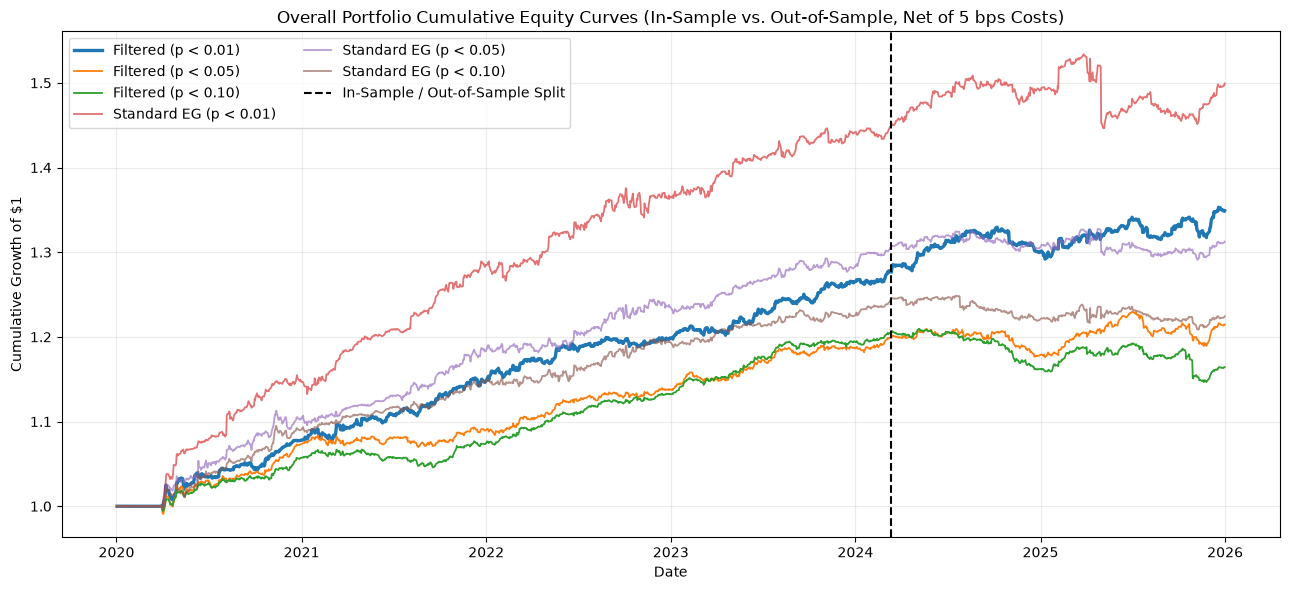

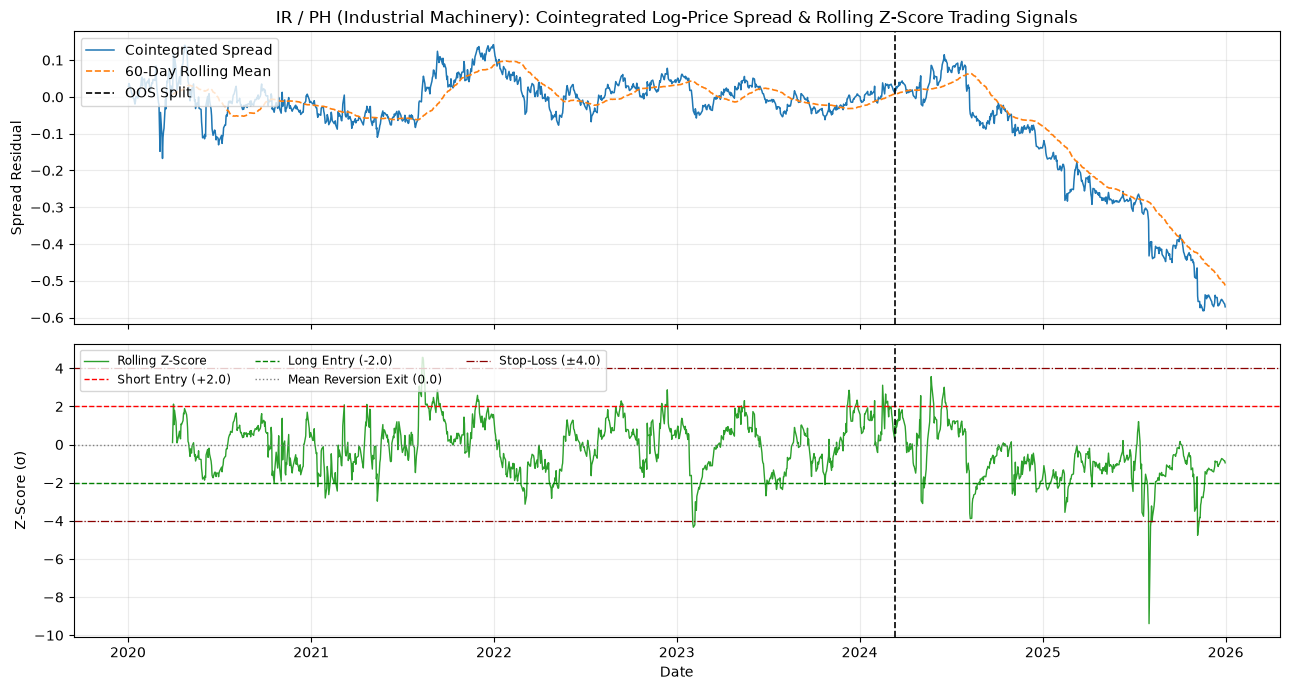

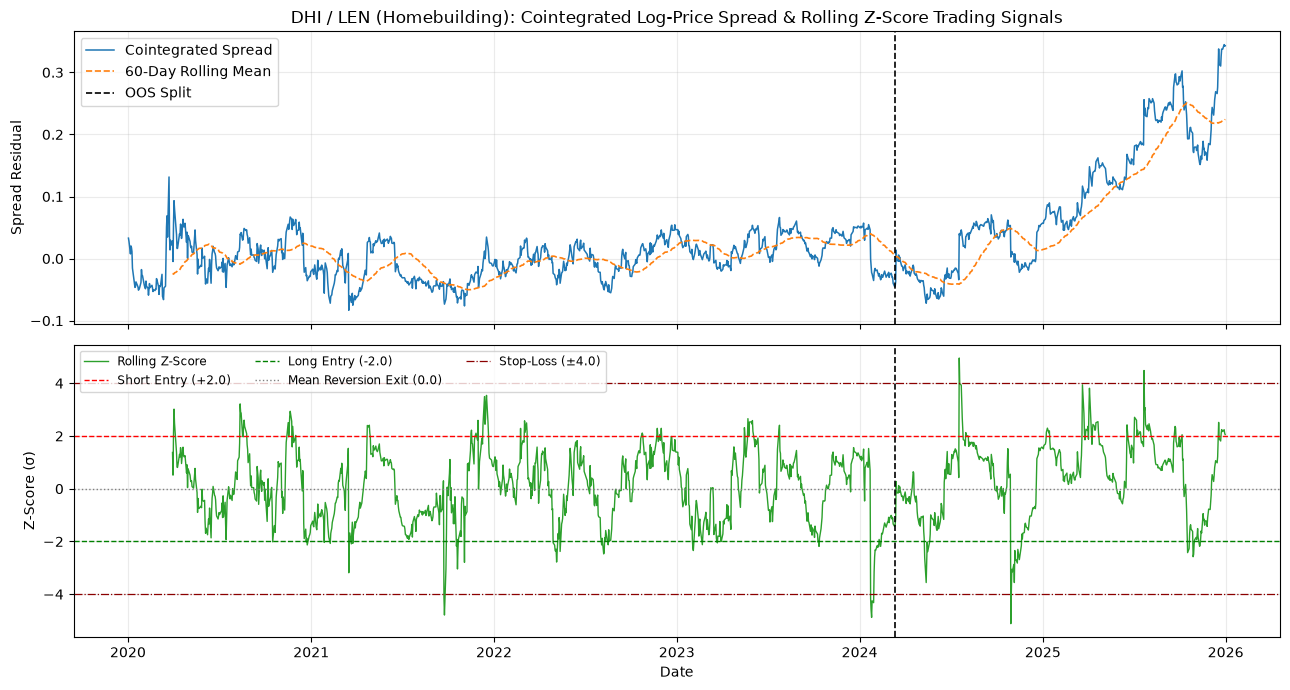

In [8]:
# 1. Chart of Cumulative Returns for Overall Portfolio (All 6 Universes)
plt.figure(figsize=(13, 6))
for name, curve in equity_curves.items():
    lw = 2.4 if "Filtered (p < 0.01)" in name else 1.3
    alpha = 1.0 if "Filtered" in name else 0.65
    plt.plot(curve.index, curve.values, label=name, linewidth=lw, alpha=alpha)

plt.axvline(split_date, color="black", linestyle="--", linewidth=1.5, label="In-Sample / Out-of-Sample Split")
plt.title("Overall Portfolio Cumulative Equity Curves (In-Sample vs. Out-of-Sample, Net of 5 bps Costs)")
plt.ylabel("Cumulative Growth of $1")
plt.xlabel("Date")
plt.legend(loc="upper left", ncol=2)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# 2. Spread Chart & Z-Score Chart with Entry/Exit Thresholds for Selected Pairs
def plot_pair_signals(pair_df: pd.DataFrame, pair_name: str, split_dt: pd.Timestamp,
                      entry_z: float = 2.0, exit_z: float = 0.0, stop_z: float = 4.0):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)

    # Top Panel: Cointegrated Spread & 60-Day Rolling Mean
    ax1.plot(pair_df.index, pair_df["spread"], label="Cointegrated Spread", color="#1f77b4", linewidth=1.1)
    ax1.plot(pair_df.index, pair_df["roll_mean"], label="60-Day Rolling Mean", color="#ff7f0e", linestyle="--", linewidth=1.2)
    ax1.axvline(split_dt, color="black", linestyle="--", linewidth=1.2, label="OOS Split")
    ax1.set_title(f"{pair_name}: Cointegrated Log-Price Spread & Rolling Z-Score Trading Signals")
    ax1.set_ylabel("Spread Residual")
    ax1.legend(loc="upper left")
    ax1.grid(alpha=0.25)

    # Bottom Panel: Rolling Z-Score & Threshold Triggers
    ax2.plot(pair_df.index, pair_df["z_score"], label="Rolling Z-Score", color="#2ca02c", linewidth=1.0)
    ax2.axhline(entry_z, color="red", linestyle="--", linewidth=1.0, label=f"Short Entry (+{entry_z})")
    ax2.axhline(-entry_z, color="green", linestyle="--", linewidth=1.0, label=f"Long Entry (-{entry_z})")
    ax2.axhline(exit_z, color="gray", linestyle=":", linewidth=1.0, label=f"Mean Reversion Exit ({exit_z})")
    ax2.axhline(stop_z, color="darkred", linestyle="-.", linewidth=0.9, label=f"Stop-Loss (±{stop_z})")
    ax2.axhline(-stop_z, color="darkred", linestyle="-.", linewidth=0.9)
    ax2.axvline(split_dt, color="black", linestyle="--", linewidth=1.2)
    ax2.set_ylabel("Z-Score (σ)")
    ax2.set_xlabel("Date")
    ax2.legend(loc="upper left", ncol=3, fontsize=8.5)
    ax2.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

# Plot top pairs from Filtered (p < 0.01)
plot_pair_signals(universe_pair_dfs["Filtered (p < 0.01)"]["IR/PH"], "IR / PH (Industrial Machinery)", split_date)
plot_pair_signals(universe_pair_dfs["Filtered (p < 0.01)"]["DHI/LEN"], "DHI / LEN (Homebuilding)", split_date)

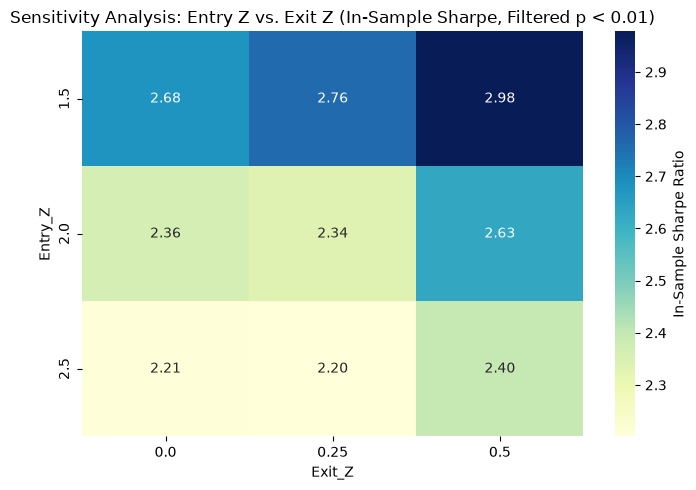

=== PARAMETER & TRANSACTION COST SENSITIVITY (Filtered p < 0.01) ===
Baseline (L=60, Static OLS, Stop=4.0, Hold=45, 5 bps)    | IS Sharpe:  2.36 (5.86%) | OOS Sharpe:  1.12 (3.12%)
Deduplicated Non-Overlapping Tickers (6 Unique Pairs)    | IS Sharpe:  2.08 (5.57%) | OOS Sharpe:  0.83 (2.67%)
Shorter Z-Lookback (L=30)                                | IS Sharpe:  2.05 (6.37%) | OOS Sharpe: -0.35 (-1.18%)
Longer Z-Lookback (L=90)                                 | IS Sharpe:  2.19 (5.01%) | OOS Sharpe:  0.68 (1.95%)
Rolling Hedge Ratio (120d OLS)                           | IS Sharpe:  0.73 (1.70%) | OOS Sharpe:  0.79 (2.65%)
Tighter Stop-Loss (Stop=3.5)                             | IS Sharpe:  2.36 (5.72%) | OOS Sharpe:  1.25 (3.38%)
Longer Max Hold (Hold=60d)                               | IS Sharpe:  2.40 (6.21%) | OOS Sharpe:  1.28 (3.64%)
Zero Friction (0 bps)                                    | IS Sharpe:  2.54 (6.33%) | OOS Sharpe:  1.30 (3.64%)
High Friction (10 bps)            

In [9]:
target_pairs = pair_universes["Filtered (p < 0.01)"]

# 1. Entry vs. Exit Z-Score Sensitivity Heatmap (Optimized on In-Sample Sharpe)
entry_grid = [1.5, 2.0, 2.5]
exit_grid = [0.0, 0.25, 0.5]
sens_rows = []

for ez in entry_grid:
    for xz in exit_grid:
        is_m, oos_m, _, _, _ = evaluate_universe(
            target_pairs, split_date, lookback=60, hedge_mode="static",
            entry_z=ez, exit_z=xz, stop_z=4.0, max_hold=45, cost_bps=5.0
        )
        sens_rows.append({
            "Entry_Z": ez,
            "Exit_Z": xz,
            "IS_Sharpe": is_m["_raw_sharpe"],
            "OOS_Sharpe": oos_m["_raw_sharpe"]
        })

sens_df = pd.DataFrame(sens_rows)
is_pivot = sens_df.pivot(index="Entry_Z", columns="Exit_Z", values="IS_Sharpe")

plt.figure(figsize=(7, 5))
sns.heatmap(is_pivot, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={"label": "In-Sample Sharpe Ratio"})
plt.title("Sensitivity Analysis: Entry Z vs. Exit Z (In-Sample Sharpe, Filtered p < 0.01)")
plt.tight_layout()
plt.show()

# 2. Secondary Parameter & Transaction Cost Sweep
print("=== PARAMETER & TRANSACTION COST SENSITIVITY (Filtered p < 0.01) ===")
param_tests = [
    ("Baseline (L=60, Static OLS, Stop=4.0, Hold=45, 5 bps)", dict(lookback=60, hedge_mode="static", stop_z=4.0, max_hold=45, cost_bps=5.0)),
    ("Deduplicated Non-Overlapping Tickers (6 Unique Pairs)", dict(lookback=60, hedge_mode="static", stop_z=4.0, max_hold=45, cost_bps=5.0, deduplicate_hubs=True)),
    ("Shorter Z-Lookback (L=30)", dict(lookback=30, hedge_mode="static", stop_z=4.0, max_hold=45, cost_bps=5.0)),
    ("Longer Z-Lookback (L=90)", dict(lookback=90, hedge_mode="static", stop_z=4.0, max_hold=45, cost_bps=5.0)),
    ("Rolling Hedge Ratio (120d OLS)", dict(lookback=60, hedge_mode="rolling", hedge_lookback=120, stop_z=4.0, max_hold=45, cost_bps=5.0)),
    ("Tighter Stop-Loss (Stop=3.5)", dict(lookback=60, hedge_mode="static", stop_z=3.5, max_hold=45, cost_bps=5.0)),
    ("Longer Max Hold (Hold=60d)", dict(lookback=60, hedge_mode="static", stop_z=4.0, max_hold=60, cost_bps=5.0)),
    ("Zero Friction (0 bps)", dict(lookback=60, hedge_mode="static", stop_z=4.0, max_hold=45, cost_bps=0.0)),
    ("High Friction (10 bps)", dict(lookback=60, hedge_mode="static", stop_z=4.0, max_hold=45, cost_bps=10.0)),
    ("Severe Friction (15 bps)", dict(lookback=60, hedge_mode="static", stop_z=4.0, max_hold=45, cost_bps=15.0)),
]

for desc, kw in param_tests:
    is_m, oos_m, _, _, _ = evaluate_universe(target_pairs, split_date, entry_z=2.0, exit_z=0.0, **kw)
    print(f"{desc:<56} | IS Sharpe: {is_m['Sharpe']:>5.2f} ({is_m['Ann_Ret']}) | OOS Sharpe: {oos_m['Sharpe']:>5.2f} ({oos_m['Ann_Ret']})")

# 3. Diagnostic Check: Do Candidate Pairs Remain Cointegrated Out-of-Sample?
oos_checks = []
for _, row in target_pairs.iterrows():
    a, b = row["Stock_A"], row["Stock_B"]
    _, p_ab, _ = coint(out_of_sample[a], out_of_sample[b])
    _, p_ba, _ = coint(out_of_sample[b], out_of_sample[a])
    oos_checks.append({
        "Pair": f"{a}/{b}",
        "Sub_Industry": row["Sub_Industry"],
        "IS_p_max": round(row["p_value_max"], 4),
        "OOS_p_max": round(max(p_ab, p_ba), 4),
        "Survives_OOS (p < 0.10)": max(p_ab, p_ba) < 0.10
    })

print("\n=== OUT-OF-SAMPLE COINTEGRATION PERSISTENCE CHECK (Filtered p < 0.01) ===")
print(pd.DataFrame(oos_checks).to_string(index=False))

=== OUT-OF-SAMPLE COINTEGRATION SURVIVAL SUMMARY ACROSS ALL 6 UNIVERSES ===
              Universe  Pairs  IS_p_Mean  OOS_p_ab_Median OOS_EG_p<0.05  OOS_EG_p<0.10 OOS_BiDir_p<0.10 Frozen_ADF_p<0.05 Frozen_ADF_p<0.10  OOS_Corr_Mean Med_Beta_Drift_%
   Filtered (p < 0.01)      8     0.0039           0.5628    0/8 (0.0%)     0/8 (0.0%)       0/8 (0.0%)        0/8 (0.0%)        0/8 (0.0%)          0.679            42.8%
   Filtered (p < 0.05)     14     0.0144           0.5793   0/14 (0.0%)    0/14 (0.0%)      0/14 (0.0%)       0/14 (0.0%)       0/14 (0.0%)          0.690            35.3%
   Filtered (p < 0.10)     21     0.0357           0.5953   0/21 (0.0%)    0/21 (0.0%)      0/21 (0.0%)       0/21 (0.0%)       0/21 (0.0%)          0.682            35.6%
Standard EG (p < 0.01)     37     0.0045           0.3799   1/37 (2.7%)    3/37 (8.1%)      2/37 (5.4%)       1/37 (2.7%)       1/37 (2.7%)          0.569            74.8%
Standard EG (p < 0.05)    113     0.0186           0.3799 10/113

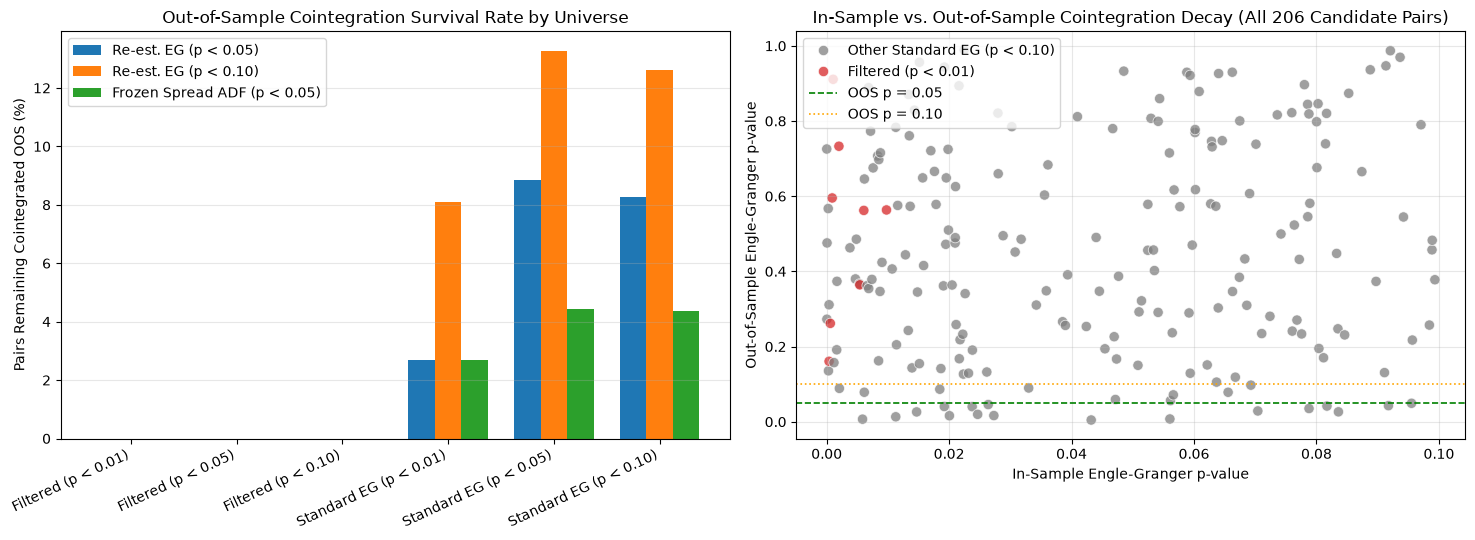

In [ ]:
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.tsa.stattools import coint, adfuller
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load processed log-price splits and all 6 candidate pair universes
in_sample = pd.read_csv("data/processed/sp500_in_sample.csv", index_col=0, parse_dates=True)
out_of_sample = pd.read_csv("data/processed/sp500_out_of_sample.csv", index_col=0, parse_dates=True)

pair_universes = {
    "Filtered (p < 0.01)": pd.read_csv("data/processed/filtered_coint_pairs_p0.01.csv"),
    "Filtered (p < 0.05)": pd.read_csv("data/processed/filtered_coint_pairs_p0.05.csv"),
    "Filtered (p < 0.10)": pd.read_csv("data/processed/filtered_coint_pairs_p0.1.csv"),
    "Standard EG (p < 0.01)": pd.read_csv("data/processed/standard_coint_pairs_p0.01.csv"),
    "Standard EG (p < 0.05)": pd.read_csv("data/processed/standard_coint_pairs_p0.05.csv"),
    "Standard EG (p < 0.10)": pd.read_csv("data/processed/standard_coint_pairs_p0.1.csv"),
}

oos_returns = out_of_sample.diff().dropna()

# Helper: Ornstein-Uhlenbeck Half-Life of Mean Reversion
def calculate_half_life(spread: pd.Series) -> float:
    spread_lag = spread.shift(1).dropna()
    spread_ret = spread.diff().dropna()
    model = sm.OLS(spread_ret, sm.add_constant(spread_lag)).fit()
    lam = model.params.iloc[1]
    if lam >= 0 or (1 + lam) <= 0:
        return np.inf
    return -np.log(2) / np.log(1 + lam)

# 2. Cached OOS evaluation per unique (Stock_A, Stock_B) pair to avoid duplicate regressions
oos_cache = {}

def evaluate_pair_oos(a: str, b: str) -> dict:
    key = (a, b)
    if key in oos_cache:
        return oos_cache[key]

    # A. Re-estimated Out-of-Sample Engle-Granger (one-way & bidirectional)
    t_ab, p_ab, _ = coint(out_of_sample[a], out_of_sample[b])
    _, p_ba, _ = coint(out_of_sample[b], out_of_sample[a])
    p_oos_max = max(p_ab, p_ba)

    # B. Frozen In-Sample Hedge Ratio -> OOS Spread Stationarity (ADF)
    ols_is = sm.OLS(in_sample[a], sm.add_constant(in_sample[b])).fit()
    alpha_is = ols_is.params["const"]
    beta_is = ols_is.params[b]
    frozen_spread_oos = out_of_sample[a] - (alpha_is + beta_is * out_of_sample[b])
    adf_stat_frozen, p_adf_frozen, *_ = adfuller(frozen_spread_oos, result_object=False)
    hl_frozen_oos = calculate_half_life(frozen_spread_oos)

    # C. Re-estimated OOS Hedge Ratio & Beta Drift
    ols_oos = sm.OLS(out_of_sample[a], sm.add_constant(out_of_sample[b])).fit()
    beta_oos = ols_oos.params[b]
    beta_drift_pct = abs(beta_oos - beta_is) / abs(beta_is) * 100.0 if beta_is != 0 else np.nan
    reest_spread_oos = out_of_sample[a] - (ols_oos.params["const"] + beta_oos * out_of_sample[b])
    hl_reest_oos = calculate_half_life(reest_spread_oos)

    # D. OOS Daily Return Correlation
    oos_corr = oos_returns[a].corr(oos_returns[b])

    res = {
        "OOS_t_stat": t_ab,
        "OOS_p_ab": p_ab,
        "OOS_p_ba": p_ba,
        "OOS_p_max": p_oos_max,
        "Frozen_ADF_stat": adf_stat_frozen,
        "Frozen_ADF_p": p_adf_frozen,
        "Beta_IS": beta_is,
        "Beta_OOS": beta_oos,
        "Beta_Drift_%": beta_drift_pct,
        "OOS_Return_Corr": oos_corr,
        "OOS_HalfLife_Reest": hl_reest_oos,
        "OOS_HalfLife_Frozen": hl_frozen_oos,
    }
    oos_cache[key] = res
    return res

# 3. Run verification across all 6 universes
universe_summaries = []
all_pair_records = []

for label, df in pair_universes.items():
    p_col = "p_value_max" if "p_value_max" in df.columns else "p_value"
    uni_rows = []

    for _, row in df.iterrows():
        a, b = row["Stock_A"], row["Stock_B"]
        if a not in out_of_sample.columns or b not in out_of_sample.columns:
            continue

        oos_stats = evaluate_pair_oos(a, b)
        record = {
            "Universe": label,
            "Pair": f"{a}/{b}",
            "Stock_A": a,
            "Stock_B": b,
            "IS_p": row[p_col],
            "IS_Return_Corr": row["Return_Corr"],
            **oos_stats,
        }
        uni_rows.append(record)
        all_pair_records.append(record)

    uni_df = pd.DataFrame(uni_rows)
    n = len(uni_df)

    universe_summaries.append({
        "Universe": label,
        "Pairs": n,
        "IS_p_Mean": round(uni_df["IS_p"].mean(), 4),
        "OOS_p_ab_Median": round(uni_df["OOS_p_ab"].median(), 4),
        "OOS_EG_p<0.05": f"{(uni_df['OOS_p_ab'] < 0.05).sum()}/{n} ({(uni_df['OOS_p_ab'] < 0.05).mean():.1%})",
        "OOS_EG_p<0.10": f"{(uni_df['OOS_p_ab'] < 0.10).sum()}/{n} ({(uni_df['OOS_p_ab'] < 0.10).mean():.1%})",
        "OOS_BiDir_p<0.10": f"{(uni_df['OOS_p_max'] < 0.10).sum()}/{n} ({(uni_df['OOS_p_max'] < 0.10).mean():.1%})",
        "Frozen_ADF_p<0.05": f"{(uni_df['Frozen_ADF_p'] < 0.05).sum()}/{n} ({(uni_df['Frozen_ADF_p'] < 0.05).mean():.1%})",
        "Frozen_ADF_p<0.10": f"{(uni_df['Frozen_ADF_p'] < 0.10).sum()}/{n} ({(uni_df['Frozen_ADF_p'] < 0.10).mean():.1%})",
        "OOS_Corr_Mean": round(uni_df["OOS_Return_Corr"].mean(), 3),
        "Med_Beta_Drift_%": f"{uni_df['Beta_Drift_%'].median():.1f}%",
        # Raw rates for plotting
        "_rate_eg05": (uni_df["OOS_p_ab"] < 0.05).mean() * 100,
        "_rate_eg10": (uni_df["OOS_p_ab"] < 0.10).mean() * 100,
        "_rate_adf05": (uni_df["Frozen_ADF_p"] < 0.05).mean() * 100,
    })

summary_df = pd.DataFrame(universe_summaries)
all_oos_df = pd.DataFrame(all_pair_records)

# Save full results to CSV
display_cols = [c for c in summary_df.columns if not c.startswith("_")]
summary_df[display_cols].to_csv("data/processed/oos_cointegration_summary.csv", index=False)
all_oos_df.to_csv("data/processed/oos_cointegration_all_pairs.csv", index=False)

print("=== OUT-OF-SAMPLE COINTEGRATION SURVIVAL SUMMARY ACROSS ALL 6 UNIVERSES ===")
print(summary_df[display_cols].to_string(index=False))

# 4. Detailed Pair-Level Inspection: Filtered (p < 0.01) & Top Surviving Pairs Overall
print("\n=== DETAILED OOS CHECK: FILTERED (p < 0.01) ===")
f01 = all_oos_df[all_oos_df["Universe"] == "Filtered (p < 0.01)"].sort_values("OOS_p_max")
print(f01[[
    "Pair", "IS_p", "OOS_p_ab", "OOS_p_max", "Frozen_ADF_p",
    "Beta_IS", "Beta_OOS", "Beta_Drift_%", "OOS_Return_Corr"
]].round(4).to_string(index=False))

print("\n=== TOP 15 SURVIVING PAIRS OUT-OF-SAMPLE (UNIQUE PAIRS ACROSS ALL UNIVERSES) ===")
unique_oos = (
    all_oos_df.sort_values("Universe")  # Keeps Filtered label if pair appears in multiple tiers
    .drop_duplicates(subset=["Pair"], keep="first")
    .sort_values("OOS_p_max")
)
print(unique_oos.head(15)[[
    "Pair", "Universe", "IS_p", "OOS_p_ab", "OOS_p_max", "Frozen_ADF_p", "Beta_Drift_%", "OOS_Return_Corr"
]].round(4).to_string(index=False))

# 5. Visualization: Survival Rates by Universe & IS vs. OOS p-value Decay
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Panel A: Survival Rate Comparison
x = np.arange(len(summary_df))
width = 0.25
axes[0].bar(x - width, summary_df["_rate_eg05"], width, label="Re-est. EG (p < 0.05)", color="#1f77b4")
axes[0].bar(x, summary_df["_rate_eg10"], width, label="Re-est. EG (p < 0.10)", color="#ff7f0e")
axes[0].bar(x + width, summary_df["_rate_adf05"], width, label="Frozen Spread ADF (p < 0.05)", color="#2ca02c")
axes[0].set_xticks(x)
axes[0].set_xticklabels(summary_df["Universe"], rotation=25, ha="right")
axes[0].set_ylabel("Pairs Remaining Cointegrated OOS (%)")
axes[0].set_title("Out-of-Sample Cointegration Survival Rate by Universe")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Panel B: IS p-value vs. OOS p-value (Unique pairs from Standard EG p<0.10, highlighting Filtered p<0.01)
plot_df = all_oos_df[all_oos_df["Universe"] == "Standard EG (p < 0.10)"].copy()
filtered_p01_set = set(f01["Pair"])
plot_df["Group"] = np.where(plot_df["Pair"].isin(filtered_p01_set), "Filtered (p < 0.01)", "Other Standard EG (p < 0.10)")

sns.scatterplot(
    data=plot_df, x="IS_p", y="OOS_p_ab", hue="Group",
    palette={"Filtered (p < 0.01)": "#d62728", "Other Standard EG (p < 0.10)": "#7f7f7f"},
    alpha=0.75, s=55, ax=axes[1]
)
axes[1].axhline(0.05, color="green", linestyle="--", linewidth=1.2, label="OOS p = 0.05")
axes[1].axhline(0.10, color="orange", linestyle=":", linewidth=1.2, label="OOS p = 0.10")
axes[1].set_xlabel("In-Sample Engle-Granger p-value")
axes[1].set_ylabel("Out-of-Sample Engle-Granger p-value")
axes[1].set_title("In-Sample vs. Out-of-Sample Cointegration Decay (All 206 Candidate Pairs)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()